# Sequential Data and Recurrent Neural Networks

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import seaborn as snss
import pandas as pd
plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'in'
plt.rcParams['axes.grid'] = True
plt.rcParams['axes.axisbelow'] = True
plt.rcParams['figure.dpi'] = 150

In [2]:
# Check available hardware
import torch
if torch.cuda.is_available():
    print(f'GPU is available, using GPU {torch.cuda.get_device_name(0)}')
    device = torch.device('cuda')
elif torch.mps.is_available():
    print(f'Apple Metal Performance Shaders framework is available, using {torch.device("mps")}')
    device = torch.device('mps')
else:
    print(f'Hardware acceleration not available, using CPU')
    device = torch.device('cpu')

GPU is available, using GPU Tesla T4


## Example with toy sequences

In [3]:
x_seq = torch.FloatTensor([[1,], [2,], [3,]])
x_seq = x_seq.repeat(1, 2)
print(f"x_seq has shape {x_seq.shape} which means it is a sequence of {x_seq.shape[0]} {x_seq.shape[1]}-dimensional vectors")

x_seq has shape torch.Size([3, 2]) which means it is a sequence of 3 2-dimensional vectors


An RNN has a hidden state $h^{(t)}$ which receives two inputs: 

- the previous hidden state $h^{(t-1)}$
- the current input $x^{(t)}$

In [4]:
import torch.nn as nn
import torch.nn.functional as F

class RNN_Cell(nn.Module):
    def __init__(self, input_size=2, hidden_size=4):
        super().__init__()

        self.hidden_size = hidden_size

        # Weight and bias connecting previous hidden state
        self.w_hh = nn.Parameter(torch.randn(size=(hidden_size, hidden_size)))
        self.b_hh = nn.Parameter(torch.zeros(hidden_size))

        # Weight and bias connecting inputs
        self.w_ih = nn.Parameter(torch.randn(size=(hidden_size, input_size)))
        self.b_ih = nn.Parameter(torch.zeros(hidden_size))

    def forward(self, x):
        """ x has size [B, t, c]
        """
        B, T, C = x.shape
        ht = torch.zeros([B, self.hidden_size], device=x.device, dtype=x.dtype)
        ot = torch.zeros([B, T, self.hidden_size], device=x.device, dtype=x.dtype)
        for t in range(T):
            xt = x[:, t, :]
            print(f'At t = {t}')
            print(f'\tInput = {xt.numpy()}')
            ht = xt @ self.w_ih.T + self.b_ih + \
                 ht @ self.w_hh.T + self.b_hh
            ht = F.tanh(ht)
            print(f'\tHidden = {ht.detach().numpy()}')
            ot[:, t, :] = ht
        return ot, ht

torch_RNN = nn.RNN(input_size=2, hidden_size=4, batch_first=True)
print("Ground truth")
print("------------")
output, hidden = torch_RNN(x_seq[None])
print(f"Output is of size {output.shape}")
print(output)
print()
print(f"Last hidden is of size {hidden.shape}")
print(hidden)

print()
print("Our implementation")
print("------------------")
np.set_printoptions(precision=4)
cell = RNN_Cell()
with torch.no_grad():
    cell.w_hh[:] = torch_RNN.weight_hh_l0
    cell.b_hh[:] = torch_RNN.bias_hh_l0
    cell.w_ih[:] = torch_RNN.weight_ih_l0
    cell.b_ih[:] = torch_RNN.bias_ih_l0

output, hidden = cell(x_seq[None])

print()
print(f"Output is of size {output.shape}")
print(output)
print()
print(f"Last hidden is of size {hidden.shape}")
print(hidden)       

Ground truth
------------
Output is of size torch.Size([1, 3, 4])
tensor([[[ 0.0313,  0.3951, -0.0128,  0.5600],
         [ 0.2979,  0.5596,  0.4226,  0.7452],
         [ 0.5673,  0.7764,  0.5796,  0.8714]]], grad_fn=<TransposeBackward1>)

Last hidden is of size torch.Size([1, 1, 4])
tensor([[[0.5673, 0.7764, 0.5796, 0.8714]]], grad_fn=<StackBackward0>)

Our implementation
------------------
At t = 0
	Input = [[1. 1.]]
	Hidden = [[ 0.0313  0.3951 -0.0128  0.56  ]]
At t = 1
	Input = [[2. 2.]]
	Hidden = [[0.2979 0.5596 0.4226 0.7452]]
At t = 2
	Input = [[3. 3.]]
	Hidden = [[0.5673 0.7764 0.5796 0.8714]]

Output is of size torch.Size([1, 3, 4])
tensor([[[ 0.0313,  0.3951, -0.0128,  0.5600],
         [ 0.2979,  0.5596,  0.4226,  0.7452],
         [ 0.5673,  0.7764,  0.5796,  0.8714]]], grad_fn=<CopySlices>)

Last hidden is of size torch.Size([1, 4])
tensor([[0.5673, 0.7764, 0.5796, 0.8714]], grad_fn=<TanhBackward0>)


## Classification example: IMDB sentiment database

In [5]:
!pip install pyarrow==15.0.2 datasets==4.0.0 transformers==5.0.0 numpy==1.26.4

In [6]:
from datasets import load_dataset

imdb_dataset = load_dataset("stanfordnlp/imdb")

In [7]:
imdb_dataset

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})

In [8]:
from torch.utils.data import Dataset, random_split, DataLoader

class IMDBDataset(Dataset):
    def __init__(self, hf_data):
        self.hf_data = hf_data

    def __len__(self):
        return len(self.hf_data)

    def __getitem__(self, idx):
        # We can return dicts in addition to tuples
        return {
            'text': self.hf_data[idx]['text'],
            'label': self.hf_data[idx]['label']
        }

train_val_dataset = IMDBDataset(imdb_dataset['train'])
train_dataset, val_dataset = random_split(train_val_dataset, lengths=[0.8, 0.2])

loader = DataLoader(train_dataset, batch_size=1, shuffle=True)
batch = next(iter(loader))
print(batch['text'], batch['label'])

['I\'ve read a few of the reviews and I\'m kinda sad that a lot of the Story seems glossed over. Its easy to do because its not a Book, its a movie and there\'s only so much that can be done in a movie- US Or Canadian- or anywhere.<br /><br />Colm Feore does, at least for a recovering "F@g-Hag" like myself, a great job of not only playing the \'friendly neighborhood\' gay man- but playing sick. I mean, the man really can\'t get much more pale! Though, you might never know it from the strip down near the... um, end.<br /><br />If you need decrepit, there are a few SKing movies you might like.<br /><br />Being the daughter of a Recovering Alchoholic, the druggie brother {David Cubitt} was the trick for me. I\'m going to give him cred, he grew up quick- and believe me that\'s good. And, as an Aspiring writer, moimeme, I can dig a lot of his insights and overviews. But I\'m more prosy than poetic.<br /><br />I may be easy to please, but I enjoyed it. A nice story pretty well put together- 

In [9]:
train_val_dataset = imdb_dataset['train']
train_dataset, val_dataset = random_split(train_val_dataset, lengths=[0.8, 0.2])
test_dataset = imdb_dataset['test']

loader = DataLoader(train_dataset, batch_size=1, shuffle=True)
batch = next(iter(loader))
print(batch['text'], batch['label'])

["The major flaw with the film is its uninspired script. It plods back and forth between vignettes of Bettie's story and re-creations of the Klaw short films. While the Klaw re-creations are well done, it is unnecessary to recreate them in their near entirety. Page Richards, while not an amazing actress, does a decent job overall. And, at times, she does bear a remarkable resemblance to Bettie. Also of note is some faithful attention to detail. Costumes and clothing well done, as is some of the set direction. The sets are generally sparse and feel stage-y, but do feel of the era. It is sometimes surprisingly well lit, and the color palette was clearly thought-out to give the overall look a vibrant, retro feel."] tensor([0])


### Preprocessing each sample

#### Tokenization

In [10]:
import re
def tokenize(sentence):
    # Remove HTML tags - anything that starts with <, ends with >, and doesn't contain a > inside
    sentence = re.sub('<[^>]*>', '', sentence)

    # Emoticon processing
    emoticons = re.findall('(?::|;|=)(?:-)?(?:\)|\(|D|P)', sentence.lower())

    # Standardize all emoticons to make sentiment processing easier
    sentence = re.sub('[\W]+', ' ', sentence.lower()) + ' '.join(emoticons).replace('-', '')

    return sentence.split()

text = '<a href="link"/> The         Dog ran over the :-)  tree!'
tokenize(text)
# tokenize(batch['text'][0])

['the', 'dog', 'ran', 'over', 'the', 'tree', ':)']

#### Vocabulary building

In [11]:
from collections import Counter
from tqdm import tqdm
def build_vocab_counts(dataset):
    vocab = Counter()
    for sample in tqdm(dataset):
        tokens = tokenize(sample['text'])
        vocab.update(tokens)
    return vocab

vocab_counts = build_vocab_counts(train_val_dataset)

100%|██████████| 25000/25000 [00:04<00:00, 5157.32it/s]


In [12]:
sorted(vocab_counts.items(), key = lambda x: x[1], reverse=True)[:20]

[('the', 336632),
 ('and', 164102),
 ('a', 163086),
 ('of', 145850),
 ('to', 135703),
 ('is', 107312),
 ('it', 96436),
 ('in', 93954),
 ('i', 87624),
 ('this', 75964),
 ('that', 73273),
 ('s', 63588),
 ('was', 48196),
 ('as', 46930),
 ('for', 44332),
 ('with', 44121),
 ('movie', 44026),
 ('but', 42612),
 ('film', 40144),
 ('t', 34382)]

In [13]:
vocab = {
    '<pad>': 0,
    '<unk>': 1,
}
for idx, (token, count) in enumerate(sorted(vocab_counts.items(), key = lambda x: x[1], reverse=True)):
    vocab[token] = idx + 2
print(len(vocab))

75979


#### Sequence encoding

In [14]:
def encode_tokens(tokens):
    return [vocab.get(token, vocab['<unk>']) for token in tokens]

encode_tokens(tokenize(batch['text'][0]))

[2,
 669,
 3297,
 17,
 2,
 20,
 7,
 92,
 3630,
 226,
 8,
 10327,
 144,
 3,
 2583,
 199,
 7427,
 5,
 2945,
 13,
 63,
 3,
 154,
 7872,
 5,
 2,
 17338,
 347,
 107,
 136,
 2,
 17338,
 154,
 7872,
 26,
 72,
 221,
 8,
 7,
 1734,
 6,
 9119,
 96,
 9,
 67,
 741,
 6322,
 1430,
 4673,
 136,
 24,
 35,
 477,
 512,
 126,
 4,
 537,
 291,
 448,
 3,
 32,
 210,
 53,
 126,
 2069,
 4,
 1729,
 4085,
 6,
 2945,
 82,
 5,
 844,
 7,
 49,
 2744,
 683,
 6,
 1582,
 1335,
 3,
 3979,
 72,
 221,
 15,
 7,
 49,
 5,
 2,
 267,
 461,
 2,
 724,
 26,
 1214,
 9532,
 3,
 230,
 849,
 4720,
 19,
 80,
 230,
 5,
 2,
 973,
 8,
 7,
 514,
 1222,
 72,
 4003,
 3,
 2,
 1391,
 9466,
 14,
 691,
 196,
 45,
 6,
 202,
 2,
 448,
 168,
 4,
 5824,
 8426,
 230]

#### Putting it all together

In [15]:
def collate_fn(batch):
    """ This will be what DataLoader uses to process all of the samples together
    """
    texts, labels, lengths = [], [], []
    for sample in batch:
        tokens = tokenize(sample['text'])
        encoded = encode_tokens(tokens)
        texts.append(torch.tensor(encoded))
        labels.append(sample['label'])
        lengths.append(len(encoded))

    labels = torch.tensor(labels)
    lengths = torch.tensor(lengths)

    # Pad each sequence to have a common shape
    texts = nn.utils.rnn.pad_sequence(texts, batch_first=True)

    return texts, labels, lengths

loader = DataLoader(train_val_dataset, batch_size=2, shuffle=False, 
                    collate_fn=collate_fn)

batch = next(iter(loader))

print('Text batch:', batch[0].shape, batch[0].dtype)
print('Label batch:', batch[1].shape, batch[1].dtype)
print('Lengths batch:', batch[2])

Text batch: torch.Size([2, 291]) torch.int64
Label batch: torch.Size([2]) torch.int64
Lengths batch: tensor([291, 228])


In [16]:
# What does a padded sequence look like?
batch[0]

tensor([[   10,  1607,    10,   244,  1991,  4099,    38,    60,   370,  1109,
            86,     5,    31,     2,  7095,    12,  3397,     8,    54,     8,
            14,    84,   620,     9,  6811,    10,    82,   553,    12,    32,
            84,     8,    14, 19102,    34,  1190,    13,  9266,    46,     8,
           124,   792,     6,  2519,    11,   663,  1617,   111,     4,   334,
             5,   107,  1184,  3091,    10,    65,    68,     6,    66,    11,
            16,   541,     2,   112,     7,  3999,   187,     4,   185,  3924,
           452,  1425,   766,  4335,    36,   489,     6,   839,   286,    53,
            51,    44,   110,     9,   833,    53,   489,     6,  1134,    41,
         11898,     6,   229,    49,   432,     5,   650,    23,    48,     2,
           841, 26535,   196,    44,   802,   985,  1334,   140,    15,     2,
          2550,   324,     3,  1504,  1334,     9,     2,  2335,  1618,     9,
           199,  2246,  7277,     3,  1956, 19103,  

## Checking that it works

In [17]:
train_loader = DataLoader(train_dataset, batch_size=32, num_workers=2, shuffle=True, collate_fn=collate_fn)
val_loader = DataLoader(val_dataset, batch_size=32, num_workers=2, shuffle=False, collate_fn=collate_fn)
test_loader = DataLoader(test_dataset, batch_size=32, num_workers=2, shuffle=False, collate_fn=collate_fn)

In [18]:
from tqdm import tqdm
for batch in tqdm(train_loader):
    a = len(batch[0])
for batch in tqdm(val_loader):
    a = len(batch[0])
for batch in tqdm(test_loader):
    a = len(batch[1])

100%|██████████| 782/782 [00:04<00:00, 163.74it/s]


### The neural network part

In [19]:
# The embedding layer
# Role: convert the tokens (index of each word in the vocabulary) into a float-valued vector. 
# This is trainable. Ideally, similar words ("happy" "ecstatic" "joyful") get mapped to similar embeddings
#
# This is a lookup table. We don't apply activations. It just makes the network able to process the words easier

import torch.nn as nn

# If using HF tokenizer, use tokenizer.vocab_size
# If using tokenize, use len(vocab)

embedding = nn.Embedding(num_embeddings=len(vocab), #tokenizer.vocab_size,
                         embedding_dim=5,
                         padding_idx=0)

embedding(batch[0])

tensor([[[-1.5620e-01,  6.4179e-01, -4.7420e-01,  5.5939e-01,  8.2622e-01],
         [ 1.1728e+00,  1.1894e+00,  9.0472e-01,  1.2490e+00, -4.0160e-01],
         [ 1.5209e+00,  5.6073e-01,  2.9129e-01, -6.6372e-01,  9.3263e-01],
         ...,
         [ 0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00],
         [ 0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00],
         [ 0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00]],

        [[ 1.6925e-01,  9.4734e-01,  7.2052e-01, -1.4992e+00,  2.4511e-01],
         [ 2.4479e-01,  1.9726e+00,  5.7328e-02, -1.1106e+00, -3.3130e-01],
         [ 1.5121e+00, -1.7051e+00,  7.7187e-01, -1.1407e+00, -3.6206e-01],
         ...,
         [ 0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00],
         [ 0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00],
         [ 0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00]],

        [[ 9.9544e-02, -6.5435e-01, -7.4383e-01,  4.2318

In [20]:
# Embedding turns this from a list of integers into a list of vectors
embedding(batch[0]).shape

torch.Size([8, 770, 5])

In [21]:
# Packing the sequence is useful for numerical efficiency. The elements from each batch element are interleaved
# to let them be processed without wasting computation on padding elements
nn.utils.rnn.pack_padded_sequence(embedding(batch[0]), batch[2], enforce_sorted=False, batch_first=True)

PackedSequence(data=tensor([[-0.9847,  2.0702, -0.5981,  0.3003, -0.3924],
        [ 0.0995, -0.6544, -0.7438,  0.4232, -0.6944],
        [-0.5190,  1.1299, -0.2027, -0.7472,  0.5255],
        ...,
        [-0.2330,  0.3247, -0.4721, -2.4455, -0.6042],
        [ 2.1104,  1.1011, -0.6929,  0.1323, -0.0136],
        [-0.8110, -0.6696, -0.3861, -0.2679,  1.2231]],
       grad_fn=<PackPaddedSequenceBackward0>), batch_sizes=tensor([8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8,
        8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8,
        8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8,
        8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8,
        8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 7, 7,
        6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 5, 5, 5, 5, 5, 5, 5,
        5, 5, 5, 5, 5, 5, 5, 5, 5, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4,
        4, 4, 4, 

In [22]:
import torch.nn.functional as F

class RNN_Model(nn.Module):
    def __init__(self, vocab_size, embedding_dim, rnn_size, fc_size):
        super().__init__()

        self.embedding = nn.Embedding(num_embeddings=vocab_size,
                                      embedding_dim=embedding_dim,
                                      padding_idx=0)
        self.rnn = nn.RNN(embedding_dim, rnn_size, batch_first=True)
        self.fc1 = nn.Linear(rnn_size, fc_size)
        self.fc2 = nn.Linear(fc_size, 2) # Output is either positive or negative

    def forward(self, text, lengths):
        x = self.embedding(text)
        x = nn.utils.rnn.pack_padded_sequence(x, lengths, enforce_sorted=False, batch_first=True)

        x, h = self.rnn(x)
        # x is the output: the output features from at each time step
        # h is the hidden layer at the end of the sequence
        x = h[-1, :, :]

        x = self.fc1(x)
        x = F.relu(x)
        x = self.fc2(x)
        return x

torch.manual_seed(42)
model = RNN_Model(
    vocab_size=len(vocab),#tokenizer.vocab_size,
    embedding_dim=32,
    rnn_size=128,
    fc_size=128
)
model

RNN_Model(
  (embedding): Embedding(75979, 32, padding_idx=0)
  (rnn): RNN(32, 128, batch_first=True)
  (fc1): Linear(in_features=128, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=2, bias=True)
)

In [23]:
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import Adam
from torch.utils.data import DataLoader, random_split
from tqdm.notebook import tqdm, trange

def train(model, optimizer, loss_func, train_loader, val_loader, num_epochs=10):
    model = model.to(device)

    train_loss = []
    train_acc = []
    val_loss = []
    val_acc = []

    pbar_epoch = trange(num_epochs)
    for ii in pbar_epoch:
        model.train()
        train_loss_ = 0.
        train_correct_ = 0.
        for xb, yb, lengths in tqdm(train_loader, leave=False):
            # Send data to device
            xb = xb.to(device)
            yb = yb.to(device)

            # Make a prediction, compute the loss
            y_pred = model(xb, lengths.cpu().numpy())
            loss = loss_func(y_pred, yb)

            # Backpropagate, apply gradient updates, zero gradients
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()

            # Logging
            train_loss_ += loss.item() * yb.shape[0]
            train_correct_ += (torch.argmax(y_pred, dim=1) == yb).float().sum().item()
            
        train_loss.append(train_loss_ / len(train_loader.dataset))
        train_acc.append(train_correct_ / len(train_loader.dataset))

        model.eval()
        with torch.no_grad():
            val_loss_ = 0.
            val_correct_ = 0.
            for xb, yb, lengths in tqdm(val_loader, leave=False):
                # Send data to device
                xb = xb.to(device)
                yb = yb.to(device)
                
                # Make a prediction, compute the loss
                y_pred = model(xb, lengths.cpu().numpy())
                loss = loss_func(y_pred, yb)

                # Logging
                val_loss_ += loss.item() * yb.shape[0]
                val_correct_ += (torch.argmax(y_pred, dim=1) == yb).float().sum().item()
            val_loss.append(val_loss_ / len(val_loader.dataset))
            val_acc.append(val_correct_ / len(val_loader.dataset))

        pbar_epoch.set_postfix(
            epoch=f"{ii+1:03d} / {num_epochs:03d}",
            train_loss=f"{train_loss[-1]:.3f}",
            train_acc=f"{train_acc[-1]:.3f}",
            val_loss=f"{val_loss[-1]:.3f}",
            val_acc=f"{val_acc[-1]:.3f}")

    return model, (train_loss, train_acc, val_loss, val_acc)

# Define a loss function and optimizer
loss = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
model, model_stats = train(model, optimizer, loss, train_loader, val_loader, num_epochs=5)

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/625 [00:00<?, ?it/s]

  0%|          | 0/157 [00:00<?, ?it/s]

  0%|          | 0/625 [00:00<?, ?it/s]

  0%|          | 0/157 [00:00<?, ?it/s]

...

  0%|          | 0/157 [00:00<?, ?it/s]

  0%|          | 0/625 [00:00<?, ?it/s]

  0%|          | 0/157 [00:00<?, ?it/s]

  0%|          | 0/625 [00:00<?, ?it/s]

  0%|          | 0/157 [00:00<?, ?it/s]

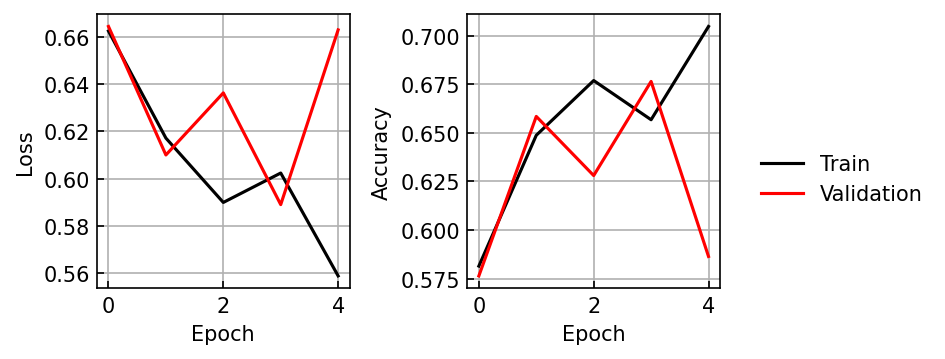

In [24]:
fig, ax = plt.subplots(1, 2, sharex=True, figsize=(5, 2.5))

ax[0].plot(model_stats[0], color='black', label='Train')
ax[0].plot(model_stats[2], color='red', label='Validation')
ax[0].set(xlabel='Epoch', ylabel='Loss')

ax[1].plot(model_stats[1], color='black', label='Train')
ax[1].plot(model_stats[3], color='red', label='Validation')
ax[1].set(xlabel='Epoch', ylabel='Accuracy')

fig.legend(*ax[1].get_legend_handles_labels(), 
           loc='center left', bbox_to_anchor=[1, 0.5], framealpha=0)

plt.tight_layout()

In [25]:
model.eval()
with torch.no_grad():
    test_correct_ = 0.
    for xb, yb, lengths in tqdm(test_loader,leave=False):
        xb = xb.to(device)
        yb = yb.to(device)
        y_pred = model(xb, lengths.cpu().numpy())
        y_pred = torch.argmax(y_pred, dim=1)
        test_correct_ += (y_pred == yb).float().sum().item()
    test_acc = test_correct_ / len(test_loader.dataset)

print(f"Test accuracy: {test_acc:.3f}")

  0%|          | 0/782 [00:00<?, ?it/s]

Test accuracy: 0.570


In [26]:
# Classify a single example
idx = np.random.choice(len(test_dataset))
sample = test_dataset[idx]
text = sample['text']
print('Comment:', text)
print()
print('True sentiment:', sample['label'])

# Convert comment with tokenizer, etc.
model.eval()
batch = collate_fn([sample,])
with torch.no_grad():
    y_pred = model(batch[0].to(device), batch[2])
    y_pred = F.softmax(y_pred, dim=1)

print('Predicted probability:', y_pred[0].cpu().numpy())

Comment: Through its 2-hour running length, Crash charts the emotional anguish of its 10-odd ensemble of characters when faced with the sometimes blatant and sometimes latent forms of racism underlying in American society. That and the emotional anguish of one of its audiences sitting near the front and desperately trying to make sense of what movies have become these days.<br /><br />The era we live in has become so complicated. Not only do we reject modernism, even the not very enthusiastic flag-waving of post-modernism ideas is always being shot down by what, post-post-modernism that aims to destroy all these ideas, all in no part thanks to the great destructivist ideas of those great 'thinkers'. But I digress. This has nothing much to do with the what the movie is about, but rather what the movie is.<br /><br />Sure, it seems hard to earn a living in a Hollywood that has to cater to a market that is so post-post-post everything that cynicism has become more than just a motto in lif

## Implementing an LSTM cell

In [27]:
x_seq = torch.FloatTensor([[1,], [2,], [3,]])
x_seq = x_seq.repeat(1, 2)
print(f"x_seq has shape {x_seq.shape} which means it is a sequence of {x_seq.shape[0]} {x_seq.shape[1]}-dimensional vectors")

x_seq has shape torch.Size([3, 2]) which means it is a sequence of 3 2-dimensional vectors


An LSTM has a hidden state $h^{(t)}$ and a cell state $c^{(t)}$.
It contains a set of **gating functions** that allow the model to input/update ($i^{(t)}$), forget ($f^{(t)}$), and output ($o^{(t)}$)

Each gate ($i^{(t)},f^{(t)},o^{(t)}$ each receive inputs from the previous hidden state $h^{(t-1)}$ and the current input $x^{(t)}$

The gating functions are given by
\begin{align}
    i^{(t)} &= \sigma\left( W_{ii} x^{(t)} + b_{ii} + W_{hi} h^{(t-1)} + b_{hi} \right) \\
    f^{(t)} &= \sigma\left( W_{if} x^{(t)} + b_{if} + W_{hf} h^{(t-1)} + b_{hf} \right) \\
    o^{(t)} &= \sigma\left( W_{io} x^{(t)} + b_{io} + W_{ho} h^{(t-1)} + b_{ho} \right) \\
\end{align}

There is also a cell input $g^{(t)}$
\begin{align}
    g^{(t)} &= \tanh \left( W_{ig} x^{(t)} + b_{ig} + W_{hg} h^{(t-1)} + b_{hg} \right) \\
\end{align}

The **cell state** $c^{(t)}$ uses the **forget gate** to determine whether to discard the previous cell state $c^{(t-1)}$ and the **input gate** to determine whether to accept the new input $g^{(t)}$

\begin{align}
    c^{(t)} &= f^{(t)} c^{(t-1)} + i^{(t)} g^{(t)}
\end{align}

The **hidden** state of the LSTM is then the product of the activated cell state and the output gate.
\begin{align}
    h^{(t)} &= o^{(t)} \tanh c^{(t)}
\end{align}

In [28]:
import torch.nn as nn
import torch.nn.functional as F

class LSTM_Cell(nn.Module):
    def __init__(self, input_size=2, hidden_size=4):
        super().__init__()

        self.hidden_size = hidden_size

        # Input gate weight and biases
        self.w_ii = nn.Parameter(torch.randn(size=(hidden_size, input_size)))
        self.b_ii = nn.Parameter(torch.zeros(hidden_size))

        self.w_ih = nn.Parameter(torch.randn(size=(hidden_size, hidden_size)))
        self.b_ih = nn.Parameter(torch.zeros(hidden_size))

        # Forget gate weight and biases
        self.w_fi = nn.Parameter(torch.randn(size=(hidden_size, input_size)))
        self.b_fi = nn.Parameter(torch.zeros(hidden_size))

        self.w_fh = nn.Parameter(torch.randn(size=(hidden_size, hidden_size)))
        self.b_fh = nn.Parameter(torch.zeros(hidden_size))

        # Cell input weight and biases
        self.w_gi = nn.Parameter(torch.randn(size=(hidden_size, input_size)))
        self.b_gi = nn.Parameter(torch.zeros(hidden_size))

        self.w_gh = nn.Parameter(torch.randn(size=(hidden_size, hidden_size)))
        self.b_gh = nn.Parameter(torch.zeros(hidden_size))
        
        # Output gate weight and biases
        self.w_oi = nn.Parameter(torch.randn(size=(hidden_size, input_size)))
        self.b_oi = nn.Parameter(torch.zeros(hidden_size))

        self.w_oh = nn.Parameter(torch.randn(size=(hidden_size, hidden_size)))
        self.b_oh = nn.Parameter(torch.zeros(hidden_size))
        
    def forward(self, x):
        """ x has size [B, t, c]
        """
        B, T, C = x.shape
        ht = torch.zeros([B, self.hidden_size], device=x.device, dtype=x.dtype)
        ct = torch.zeros([B, self.hidden_size], device=x.device, dtype=x.dtype)
        outputs = torch.zeros([B, T, self.hidden_size], device=x.device, dtype=x.dtype)
        for t in range(T):
            xt = x[:, t, :]
            print(f'At t = {t}')
            print(f'\tInput = {xt.numpy()}')

            # Compute the input/forget gates and cell inputs
            it = F.sigmoid(
                xt @ self.w_ii.T + self.b_ii + \
                ht @ self.w_ih.T + self.b_ih
            )
            ft = F.sigmoid(
                xt @ self.w_fi.T + self.b_fi + \
                ht @ self.w_fh.T + self.b_fh
            )
            gt = F.tanh(
                xt @ self.w_gi.T + self.b_gi + \
                ht @ self.w_gh.T + self.b_gh
            )

            # Compute the cell state
            ct = ft * ct + it * gt
            print(f'\tCell = {ct.detach().numpy()}')

            # Use the output gate to determine the hidden state
            ot = F.sigmoid(
                xt @ self.w_oi.T + self.b_oi + \
                ht @ self.w_oh.T + self.b_oh
            )
            ht = ot * F.tanh(ct)
            print(f'\tHidden = {ht.detach().numpy()}')
            outputs[:, t, :] = ht
        return outputs, (ht, ct)

torch_LSTM = nn.LSTM(input_size=2, hidden_size=4, batch_first=True)
print("Ground truth")
print("------------")
output, (hidden, cell) = torch_LSTM(x_seq[None])
print(f"Output is of size {output.shape}")
print(output)
print()
print(f"Last hidden is of size {hidden.shape}")
print(hidden)
print()
print(f"Last cell is of size {cell.shape}")
print(cell)

print()
print("Our implementation")
print("------------------")
np.set_printoptions(precision=4)
lstm = LSTM_Cell()
with torch.no_grad():
    lstm.w_ii[:] = torch_LSTM.weight_ih_l0[0:4]
    lstm.b_ii[:] = torch_LSTM.bias_ih_l0[0:4]
    lstm.w_ih[:] = torch_LSTM.weight_hh_l0[0:4]
    lstm.b_ih[:] = torch_LSTM.bias_hh_l0[0:4]

    lstm.w_fi[:] = torch_LSTM.weight_ih_l0[4:8]
    lstm.b_fi[:] = torch_LSTM.bias_ih_l0[4:8]
    lstm.w_fh[:] = torch_LSTM.weight_hh_l0[4:8]
    lstm.b_fh[:] = torch_LSTM.bias_hh_l0[4:8]

    lstm.w_gi[:] = torch_LSTM.weight_ih_l0[8:12]
    lstm.b_gi[:] = torch_LSTM.bias_ih_l0[8:12]
    lstm.w_gh[:] = torch_LSTM.weight_hh_l0[8:12]
    lstm.b_gh[:] = torch_LSTM.bias_hh_l0[8:12]

    lstm.w_oi[:] = torch_LSTM.weight_ih_l0[12:16]
    lstm.b_oi[:] = torch_LSTM.bias_ih_l0[12:16]
    lstm.w_oh[:] = torch_LSTM.weight_hh_l0[12:16]
    lstm.b_oh[:] = torch_LSTM.bias_hh_l0[12:16]

output, (hidden, cell) = lstm(x_seq[None])

print()
print(f"Output is of size {output.shape}")
print(output)
print()
print(f"Last hidden is of size {hidden.shape}")
print(hidden)
print()
print(f"Last cell is of size {cell.shape}")
print(cell)

Ground truth
------------
Output is of size torch.Size([1, 3, 4])
tensor([[[-0.0251, -0.0371, -0.1357,  0.0286],
         [-0.1091, -0.0206, -0.2578, -0.0543],
         [-0.1423, -0.0065, -0.3741, -0.0532]]], grad_fn=<TransposeBackward0>)

Last hidden is of size torch.Size([1, 1, 4])
tensor([[[-0.1423, -0.0065, -0.3741, -0.0532]]], grad_fn=<StackBackward0>)

Last cell is of size torch.Size([1, 1, 4])
tensor([[[-0.7170, -0.0729, -0.7173, -0.1713]]], grad_fn=<StackBackward0>)

Our implementation
------------------
At t = 0
	Input = [[1. 1.]]
	Cell = [[-0.086  -0.1008 -0.2536  0.061 ]]
	Hidden = [[-0.0251 -0.0371 -0.1357  0.0286]]
At t = 1
	Input = [[2. 2.]]
	Cell = [[-0.4374 -0.105  -0.4843 -0.138 ]]
	Hidden = [[-0.1091 -0.0206 -0.2578 -0.0543]]
At t = 2
	Input = [[3. 3.]]
	Cell = [[-0.717  -0.0729 -0.7173 -0.1713]]
	Hidden = [[-0.1423 -0.0065 -0.3741 -0.0532]]

Output is of size torch.Size([1, 3, 4])
tensor([[[-0.0251, -0.0371, -0.1357,  0.0286],
         [-0.1091, -0.0206, -0.2578, -0.

In [29]:
import torch.nn.functional as F

class LSTM_Model(nn.Module):
    def __init__(self, vocab_size, embedding_dim, rnn_size, fc_size):
        super().__init__()

        self.embedding = nn.Embedding(num_embeddings=vocab_size,
                                      embedding_dim=embedding_dim,
                                      padding_idx=0)
        self.lstm = nn.LSTM(embedding_dim, rnn_size, batch_first=True)
        self.fc1 = nn.Linear(rnn_size, fc_size)
        self.fc2 = nn.Linear(fc_size, 2) # Output is either positive or negative

    def forward(self, text, lengths):
        x = self.embedding(text)
        x = nn.utils.rnn.pack_padded_sequence(x, lengths, enforce_sorted=False, batch_first=True)

        x, (h, c) = self.lstm(x)
        # x is the output: the output features from at each time step
        # h is the hidden layer at the end of the sequence
        # c is the cell state at the end of the sequence
        x = h[-1, :, :]

        x = self.fc1(x)
        x = F.relu(x)
        x = self.fc2(x)
        return x

torch.manual_seed(42)
model = LSTM_Model(
    vocab_size=len(vocab),# tokenizer.vocab_size,
    embedding_dim=32,
    rnn_size=128,
    fc_size=128
)
model

LSTM_Model(
  (embedding): Embedding(75979, 32, padding_idx=0)
  (lstm): LSTM(32, 128, batch_first=True)
  (fc1): Linear(in_features=128, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=2, bias=True)
)

In [30]:
# Define a loss function and optimizer
loss = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
model, model_stats = train(model, optimizer, loss, train_loader, val_loader, num_epochs=5)

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/625 [00:00<?, ?it/s]

  0%|          | 0/157 [00:00<?, ?it/s]

  0%|          | 0/625 [00:00<?, ?it/s]

  0%|          | 0/157 [00:00<?, ?it/s]

...

  0%|          | 0/157 [00:00<?, ?it/s]

  0%|          | 0/625 [00:00<?, ?it/s]

  0%|          | 0/157 [00:00<?, ?it/s]

  0%|          | 0/625 [00:00<?, ?it/s]

  0%|          | 0/157 [00:00<?, ?it/s]

In [31]:
model.eval()
with torch.no_grad():
    test_correct_ = 0.
    for xb, yb, lengths in tqdm(test_loader,leave=False):
        xb = xb.to(device)
        yb = yb.to(device)
        y_pred = model(xb, lengths.cpu().numpy())
        y_pred = torch.argmax(y_pred, dim=1)
        test_correct_ += (y_pred == yb).float().sum().item()
    test_acc = test_correct_ / len(test_loader.dataset)

print(f"Test accuracy: {test_acc:.3f}")

  0%|          | 0/782 [00:00<?, ?it/s]

Test accuracy: 0.831


In [32]:
# Classify a single example
idx = np.random.choice(len(test_dataset))
sample = test_dataset[idx]
text = sample['text']
print('Comment:', text)
print()
print('True sentiment:', sample['label'])

# Convert comment with tokenizer, etc.
model.eval()
batch = collate_fn([sample,])
with torch.no_grad():
    y_pred = model(batch[0].to(device), batch[2])
    y_pred = F.softmax(y_pred, dim=1)

print('Predicted probability:', y_pred[0].cpu().numpy())

Comment: It would seem we should acknowledge Scandinavian cinema for more than merely the Dogma 1995 movement as cooked up by the Danish all those years ago. Den Brysomme Mannen, or The Bothersome Man in English, is a surreal and deeply thought through film yet deeply entertaining and rich in content both on and under the surface. As a film alone, it is a scathing comedy on society and attitudes in the post-modern world we live in; a world that judging by The Bothersome Man has reached the regions of Norway and the like. But along with this black comedy feel to it, it would seem the film delves a little deeper and raises issues, at least to me, of metaphorical religious spaces and our human instinct to want to uncover the truth amongst so much material in our world that perhaps seems alien to us.<br /><br />This was, in truth, a fantastic introduction to contemporary Norwegian cinema for me. The film very much falls into that category of the European art cannon with its deep themes and